In [2]:
import sys
from pathlib import Path

racine = Path.cwd().parent
if str(racine) not in sys.path:
    sys.path.insert(0, str(racine))

%load_ext autoreload
%autoreload 2

from src.marches import charger_tous_marches, controler_donnees

donnees = charger_tous_marches(telecharger=False)
controle = controler_donnees(donnees)
controle

,debut,fin,nb_seances,trous_jours_ouvres,seances_high_egal_low,seances_high_inf_low
marche,,,,,,
SP500,2000-01-03,2025-12-31,6539,244,0,0
CAC40,2000-01-03,2025-12-31,6645,138,1,0
NIKKEI,2000-01-04,2025-12-30,6369,414,1,0
VIX,2000-01-03,2025-12-31,6539,244,0,0


### Contrôle qualité des données (2000–2025)

Les séries couvrent bien toute la période demandée, du 3 janvier 2000 au 31 décembre 2025 pour New York et Paris (et du 4 janvier 2000 au 30 décembre 2025 pour Tokyo). Les quelques jours ouvrés manquants correspondent simplement aux jours fériés propres à chaque bourse (plus nombreux au Japon avec 414 jours contre 138 en France), que l'on conserve tels quels sans combler les trous. Enfin, il n'y a aucune donnée aberrante (`high < low` vaut 0 partout) et seulement deux séances plates (`high == low`, une sur le CAC 40 et une sur le Nikkei), ce qui valide la qualité de la base avant l'analyse.

In [3]:
from src.marches import statistiques_descriptives

stats, extremes = statistiques_descriptives(donnees)
display(stats)
extremes["SP500"]

,rendement_moyen_pct,ecart_type_pct,skewness,kurtosis,q01_pct,q99_pct,pire_journee,meilleure_journee,vol_parkinson_moy_pct,vol_gk_moy_pct,corr_parkinson_gk
marche,,,,,,,,,,,
SP500,0.0237,1.222,-0.35,10.63,-3.48,3.30,-12.77% (2020-03-16),+10.96% (2008-10-13),0.777,0.740,0.9382
CAC40,0.0048,1.374,-0.22,6.65,-4.04,3.52,-13.10% (2020-03-12),+10.59% (2008-10-13),0.893,0.889,0.9508
NIKKEI,0.0153,1.463,-0.41,7.24,-4.02,3.53,-13.23% (2024-08-05),+13.23% (2008-10-14),0.798,0.773,0.9349
VIX,-0.0074,7.157,1.02,6.88,-16.69,21.62,-44.24% (2025-04-09),+76.82% (2018-02-05),5.173,5.156,0.9539


,rendement_pct,vol_parkinson_pct
date,,
2020-03-16,-12.77,4.42
2008-10-13,10.96,5.90
2008-10-28,10.25,6.41
2020-03-12,-9.99,4.26
2008-10-15,-9.47,5.74


### Interprétation des statistiques descriptives (2000–2025)

Entre 2000 et 2025, les rendements quotidiens des trois indices boursiers s'écartent nettement d'une loi normale : leurs queues de distribution sont épaisses (kurtosis de 6,65 à 10,63) et légèrement asymétriques à gauche (skewness négatif). Les chutes brutales sont donc plus fréquentes et marquées que les hausses, comme lors du krach de mars 2020 (-12,77 % sur le S&P 500 le 16 mars et -13,10 % sur le CAC 40 le 12 mars) ou de la baisse du Nikkei le 5 août 2024 (-13,23 %). À l'inverse, le VIX réagit par des pics violents à la hausse (jusqu'à +76,82 % le 5 février 2018). Enfin, les volatilités de Parkinson et de Garman-Klass donnent des résultats très proches (corrélation supérieure à 0,93 sur tous les indices), ce qui confirme que Parkinson est un bon choix pour la suite de l'analyse.

Sur le tableau extremes["SP500"], on peut voir que les 5 plus fortes variations quotidiennes du S&P 500 sur 2000–2025 se concentrent toutes sur deux épisodes : la crise financière d'octobre 2008 et le krach Covid de mars 2020, avec des mouvements proches de ±10 % à ±13 % en une seule séance.

,rendement_moyen_pct,ecart_type_pct,skewness,kurtosis,q01_pct,q99_pct,pire_journee,meilleure_journee,vol_parkinson_moy_pct,vol_gk_moy_pct,corr_parkinson_gk
marche,,,,,,,,,,,
SP500,0.0237,1.222,-0.35,10.63,-3.48,3.30,-12.77% (2020-03-16),+10.96% (2008-10-13),0.777,0.740,0.9382
CAC40,0.0048,1.374,-0.22,6.65,-4.04,3.52,-13.10% (2020-03-12),+10.59% (2008-10-13),0.893,0.889,0.9508
NIKKEI,0.0153,1.463,-0.41,7.24,-4.02,3.53,-13.23% (2024-08-05),+13.23% (2008-10-14),0.798,0.773,0.9349
VIX,-0.0074,7.157,1.02,6.88,-16.69,21.62,-44.24% (2025-04-09),+76.82% (2018-02-05),5.173,5.156,0.9539


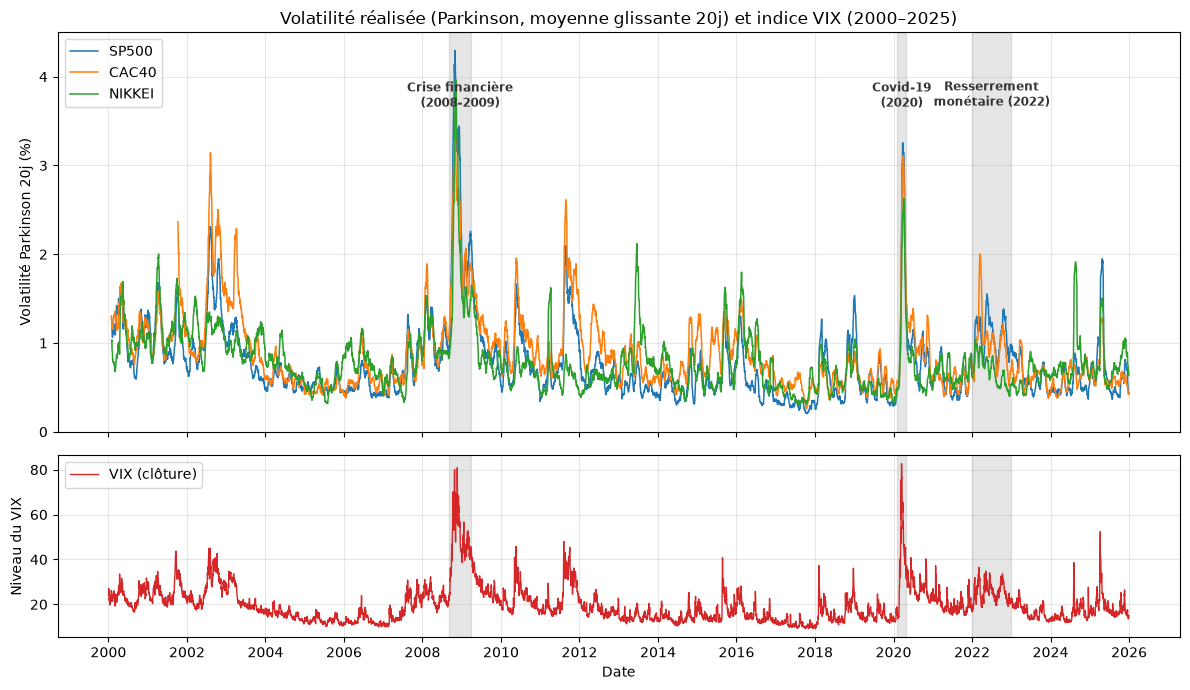

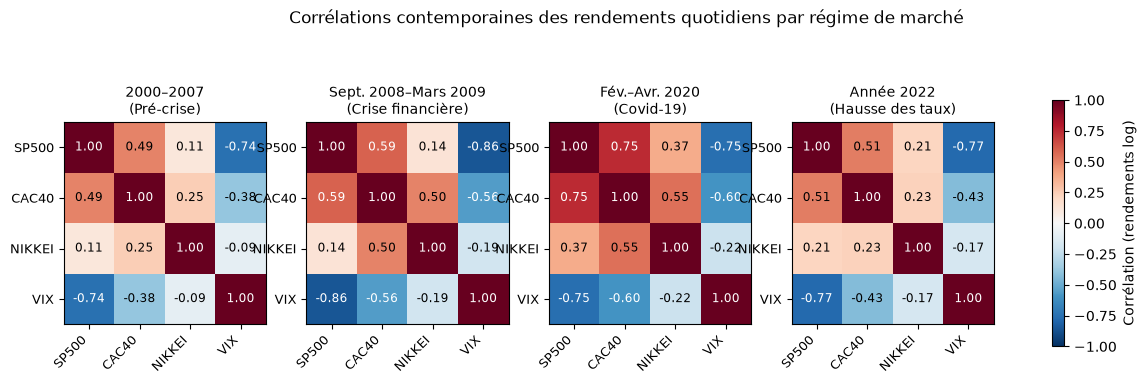

In [5]:
from src.marches import analyse, figure

display(analyse())
fig1, fig2 = figure()

### Évolution de la volatilité et corrélations entre marchés

Le premier graphique montre que les trois grands indices réagissent de manière synchrone lors des chocs majeurs[cite: 8]. La volatilité moyenne sur 20 jours bondit simultanément à New York, Paris et Tokyo pendant la crise de 2008–2009 (au-delà de 4 %) et le krach du Covid-19 en mars 2020 (au-dessus de 3 %), en parallèle des pics du VIX au-dessus de 80[cite: 8]. Le resserrement monétaire de 2022 entraîne quant à lui une tension plus modérée mais étalée sur toute l'année[cite: 8].

Les matrices de corrélation montrent que les liens entre places financières se renforcent en période de stress : la corrélation entre le S&P 500 et le CAC 40 passe de 0,49 sur 2000–2007 à 0,59 en 2008–2009 et 0,75 au printemps 2020, tandis que le VIX reste fortement corrélé négativement aux actions (jusqu'à -0,86 avec le S&P 500 en 2008–2009)[cite: 9]. Enfin, la corrélation le même jour entre le S&P 500 et le Nikkei reste faible (0,11 à 0,37) en raison du décalage horaire : Tokyo clôture avant l'ouverture de New York, ce qui motive l'étude des décalages temporels dans la partie suivante[cite: 9].